# EXP02 · Tăng số lớp Convolution

So sánh baseline 3 lớp tích chập với DeeperCNN 4 lớp, Improved V2 6 lớp và Improved V3 8 lớp trên FER2013. Chạy các ô theo thứ tự để đọc kết quả từ các lượt đã lưu trong `RUN_DIRS`.

Chọn kernel có PyTorch, pandas, scikit-learn, PyYAML, Matplotlib và TensorBoard. Đặt `train.csv` trong `BTL02/data`. Nếu dùng CUDA qua Conda trên Windows, mở Jupyter từ môi trường Conda đã kích hoạt.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display
from torch import nn

cwd = Path.cwd()
project = next(
    (path for path in (cwd, cwd.parent, cwd / "BTL02")
     if (path / "configs/exp02_more_conv.yaml").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("Mở notebook từ thư mục repo, BTL02 hoặc BTL02/notebooks.")
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from evaluate import evaluate_checkpoint
from models import build_model
from train import run_experiment, select_device
from visualize import display_saved_figures

baseline_name = "Baseline"
baseline_run = project / "results/EXP001_Baseline/20261120_122107_175923"
config_paths = {
    "DeeperCNN": project / "configs/exp02_more_conv.yaml",
    "Improved V2": project / "configs/exp02_improved_v2.yaml",
    "Improved V3": project / "configs/exp02_improved_v3.yaml",
}
configs = {
    name: yaml.safe_load(path.read_text(encoding="utf-8"))
    for name, path in config_paths.items()
}

## Kiến trúc và đối chứng

| Mô hình | Số lớp Conv | Kênh đầu ra theo từng lớp Conv | Tensor trước Flatten |
|---|---:|---|---|
| Baseline | 3 | 32 → 64 → 128 | 128 × 6 × 6 |
| DeeperCNN | 4 | 32 → 64 → 128 → 128 | 128 × 6 × 6 |
| Improved V2 | 6 | 32 → 32 → 64 → 64 → 128 → 128 | 128 × 6 × 6 |
| Improved V3 | 8 | 32 → 32 → 64 → 64 → 128 → 128 → 256 → 256 | 256 × 3 × 3 |

V2 và V3 dùng hai lớp Conv 3 × 3 có padding 1 trong mỗi khối kênh. Sau mỗi Conv là ReLU, sau mỗi khối là MaxPool 2 × 2. V3 thêm khối 256 kênh cùng một lần pooling nên phép so sánh với V2 phản ánh đồng thời thay đổi về độ sâu, số kênh và kích thước đặc trưng trước Flatten. Cả bốn mô hình dùng lớp Linear ẩn 128 nút và đầu ra 7 logits.

Các lượt dùng ảnh xám 48 × 48 chuẩn hóa về [0, 1], split phân tầng 80/20, seed 42, Adam với learning rate 0,001, batch 64, CrossEntropyLoss và 30 epoch. Baseline chạy trên CPU, còn ba biến thể EXP02 chạy trên GPU RTX 3050 Laptop.

In [2]:
baseline_config = yaml.safe_load((baseline_run / "config.yaml").read_text(encoding="utf-8"))
training_keys = ("data_dir", "epochs", "batch_size", "learning_rate", "seed", "device")
for name, config in configs.items():
    for key in training_keys:
        if config[key] != baseline_config[key]:
            raise ValueError(f"{name} khác baseline ở cấu hình {key}.")

model_keys = {baseline_name: "baseline", **{name: config["model"] for name, config in configs.items()}}
architecture = {}
for name, model_key in model_keys.items():
    model = build_model(model_key)
    channels = [layer.out_channels for layer in model.modules() if isinstance(layer, nn.Conv2d)]
    architecture[name] = {
        "Số lớp tích chập": len(channels),
        "Kênh theo từng lớp": " → ".join(map(str, channels)),
        "Số tham số": sum(parameter.numel() for parameter in model.parameters()),
    }

display(pd.DataFrame.from_dict(architecture, orient="index"))

,Số lớp tích chập,Kênh theo từng lớp,Số tham số
Baseline,3,32 → 64 → 128,683527
DeeperCNN,4,32 → 64 → 128 → 128,831111
Improved V2,6,32 → 32 → 64 → 64 → 128 → 128,877287
Improved V3,8,32 → 32 → 64 → 64 → 128 → 128 → 256 → 256,1467623


## Dùng lại kết quả đã lưu

`RUN_DIRS` trỏ đến các lượt đã hoàn tất. Đặt giá trị của một biến thể thành `None` khi cần chủ động huấn luyện lại. Mỗi lượt lưu `best.pth` tại epoch có validation loss thấp nhất. Đường dẫn được in theo dạng tương đối từ thư mục dự án.

In [3]:
RUN_DIRS = {
    "DeeperCNN": "results/EXP02/deeper_cnn/20261124_125301_044663",
    "Improved V2": "results/EXP02/improved_cnn_v2/20261124_125450_669946",
    "Improved V3": "results/EXP02/improved_cnn_v3/20261124_125802_658900",
}

runs = {baseline_name: baseline_run}
for name, config_path in config_paths.items():
    saved_path = RUN_DIRS[name]
    if saved_path is None:
        run = run_experiment(config_path)
    else:
        run = project / saved_path
        saved_config = yaml.safe_load((run / "config.yaml").read_text(encoding="utf-8"))
        for key in ("experiment", "model", *training_keys):
            if saved_config[key] != configs[name][key]:
                raise ValueError(f"Lượt đã lưu của {name} khác cấu hình ở {key}.")
    runs[name] = run
    print(f"{name} · {run.relative_to(project)}")

DeeperCNN · results\EXP02\deeper_cnn\20261124_125301_044663
Improved V2 · results\EXP02\improved_cnn_v2\20261124_125450_669946
Improved V3 · results\EXP02\improved_cnn_v3\20261124_125802_658900


## Kết quả validation và ảnh đã lưu

Các kết quả được tính trên split validation cố định từ `train.csv`.

,Validation accuracy (%),Validation macro F1
Baseline,55.2072,0.4861
DeeperCNN,54.4584,0.4874
Improved V2,56.0432,0.4875
Improved V3,53.2741,0.4582


Baseline


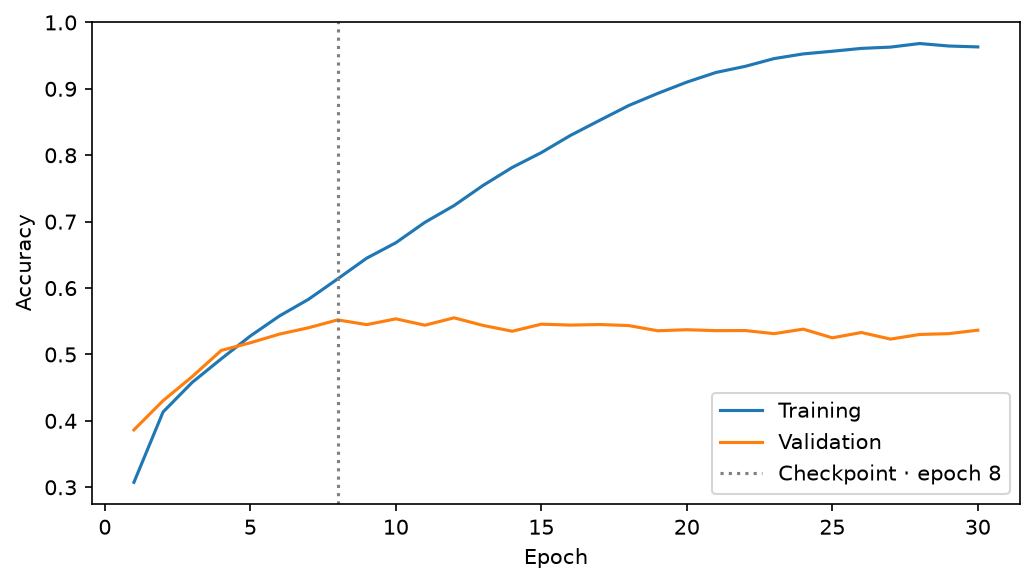

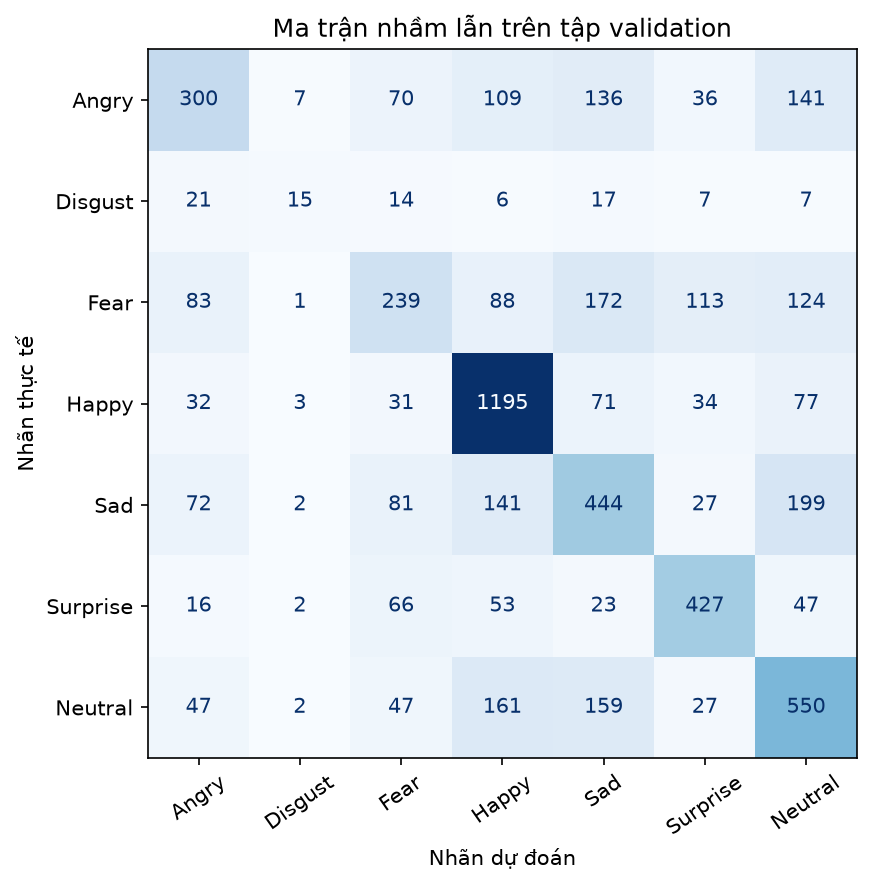

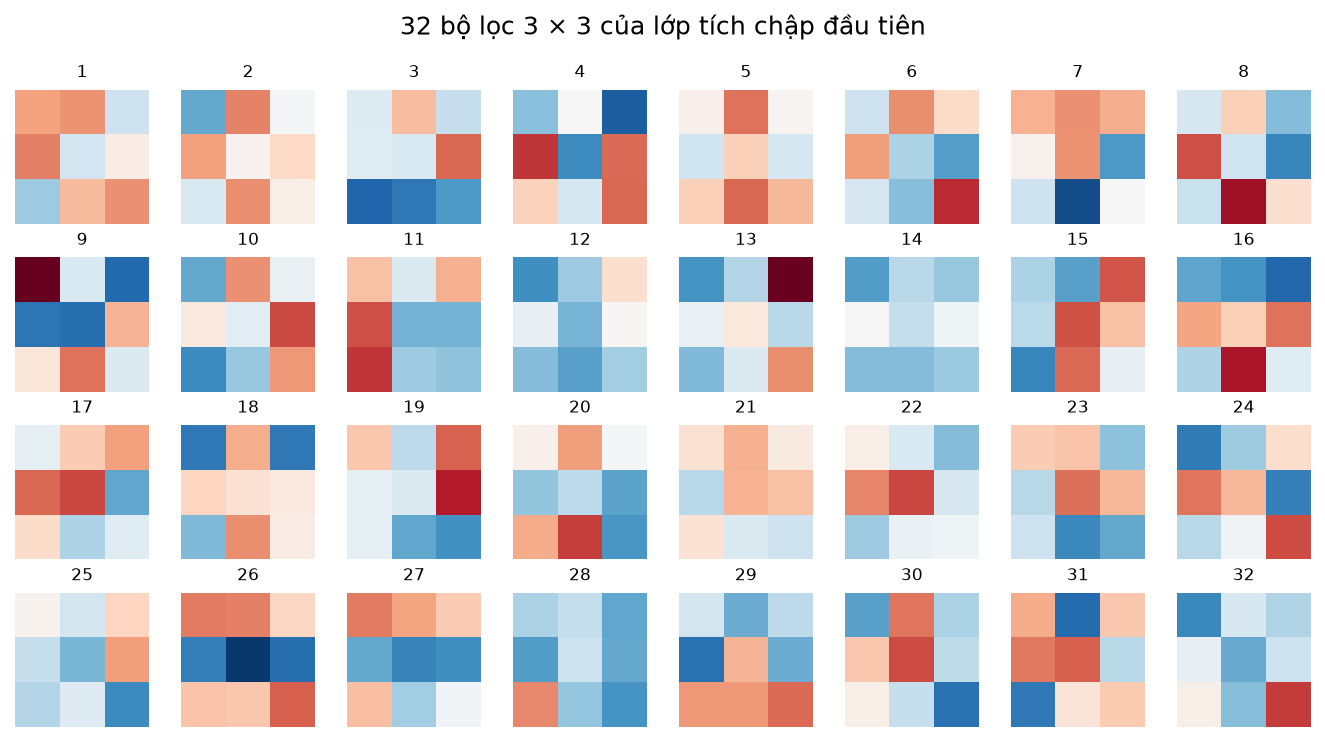

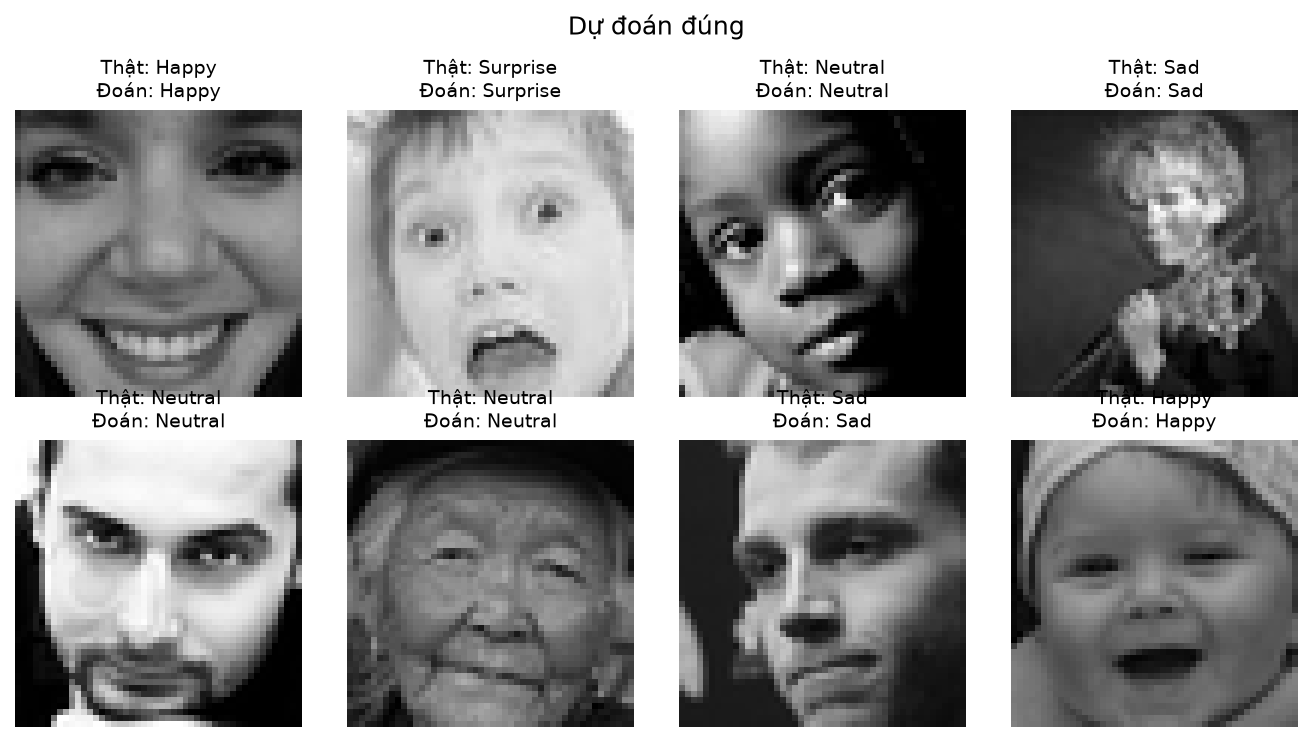

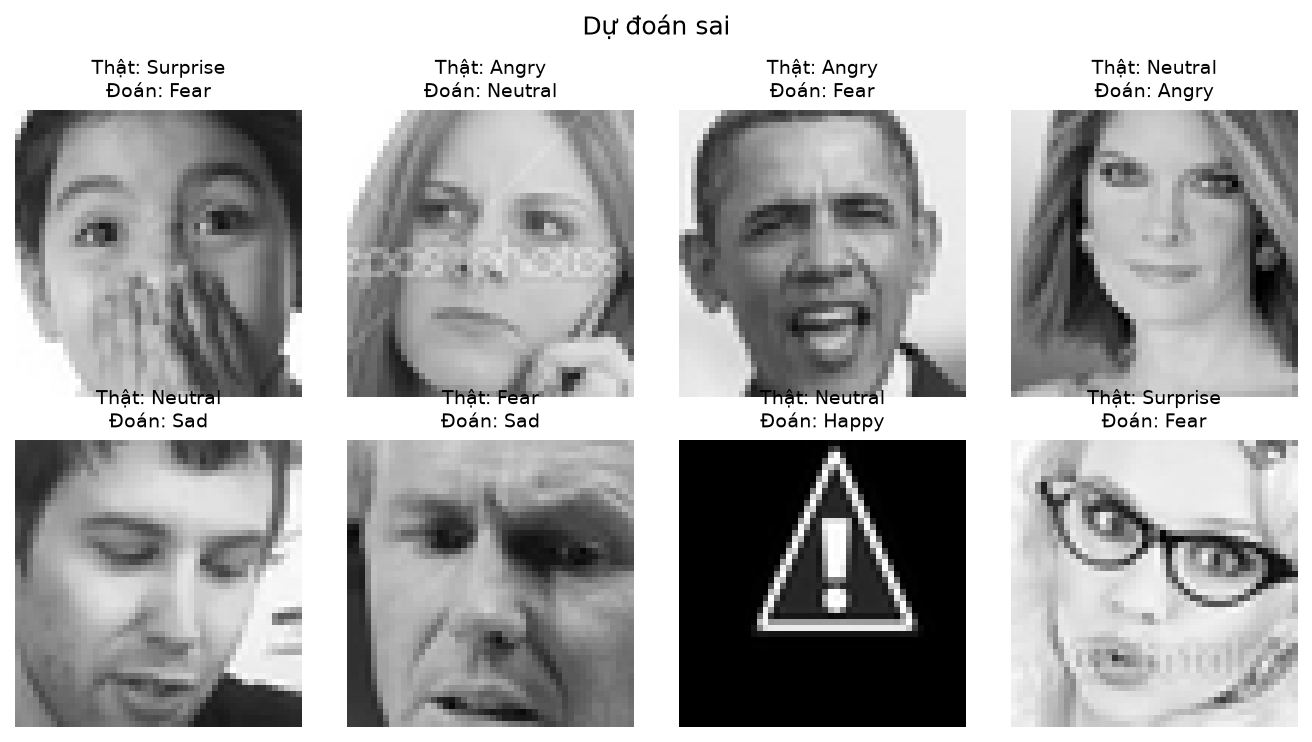

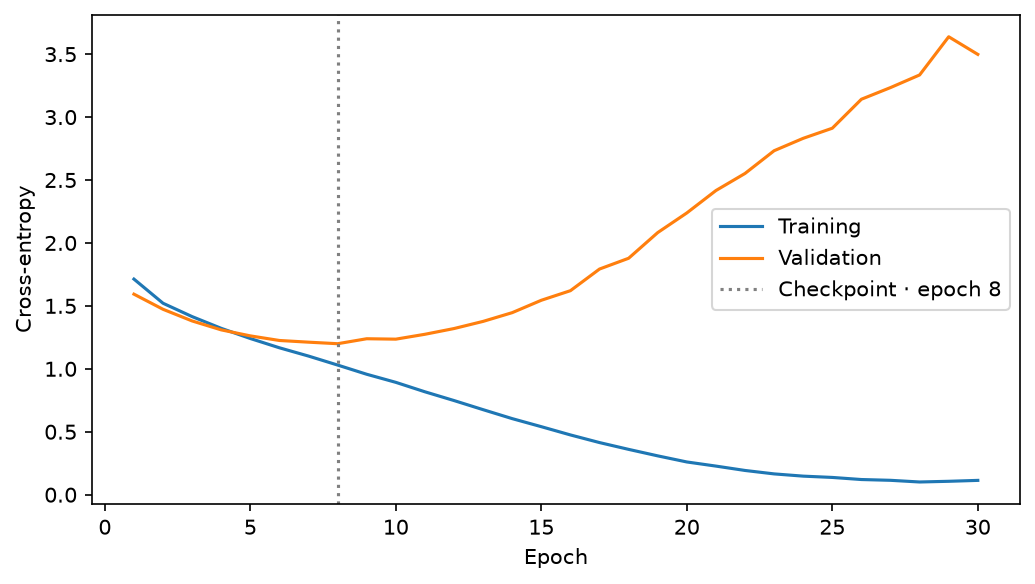

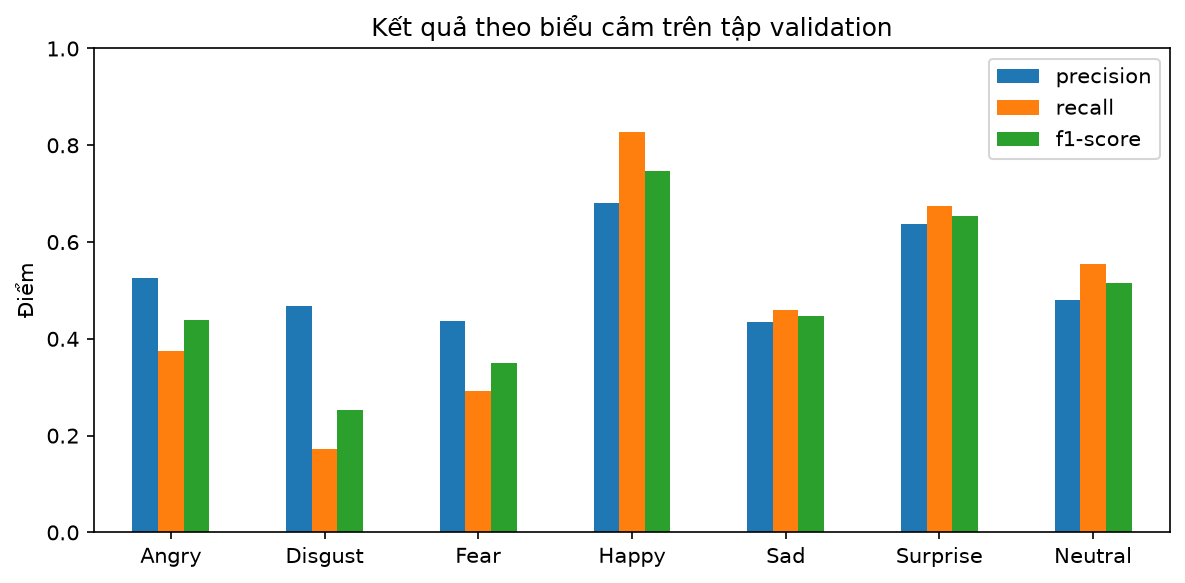

DeeperCNN


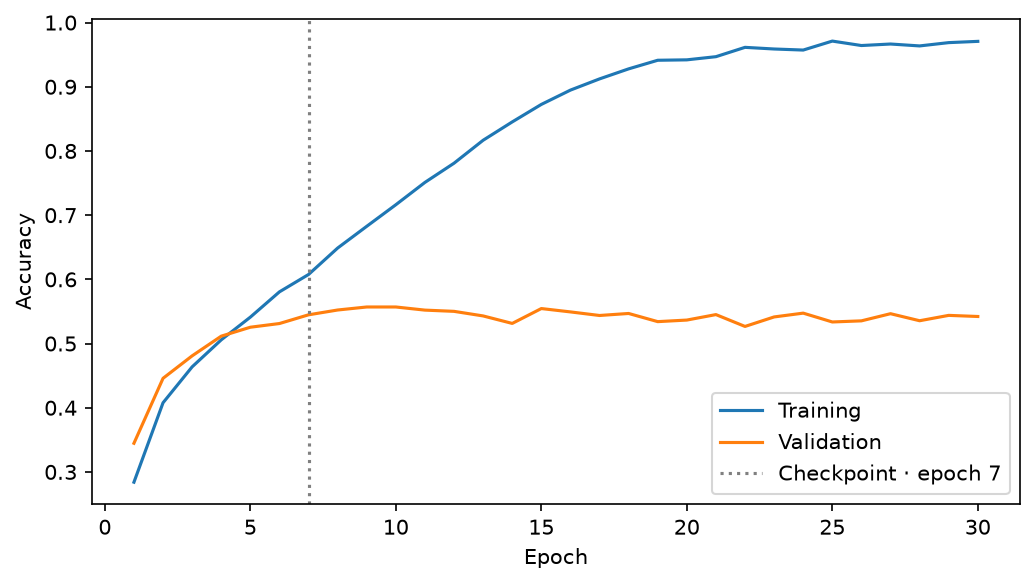

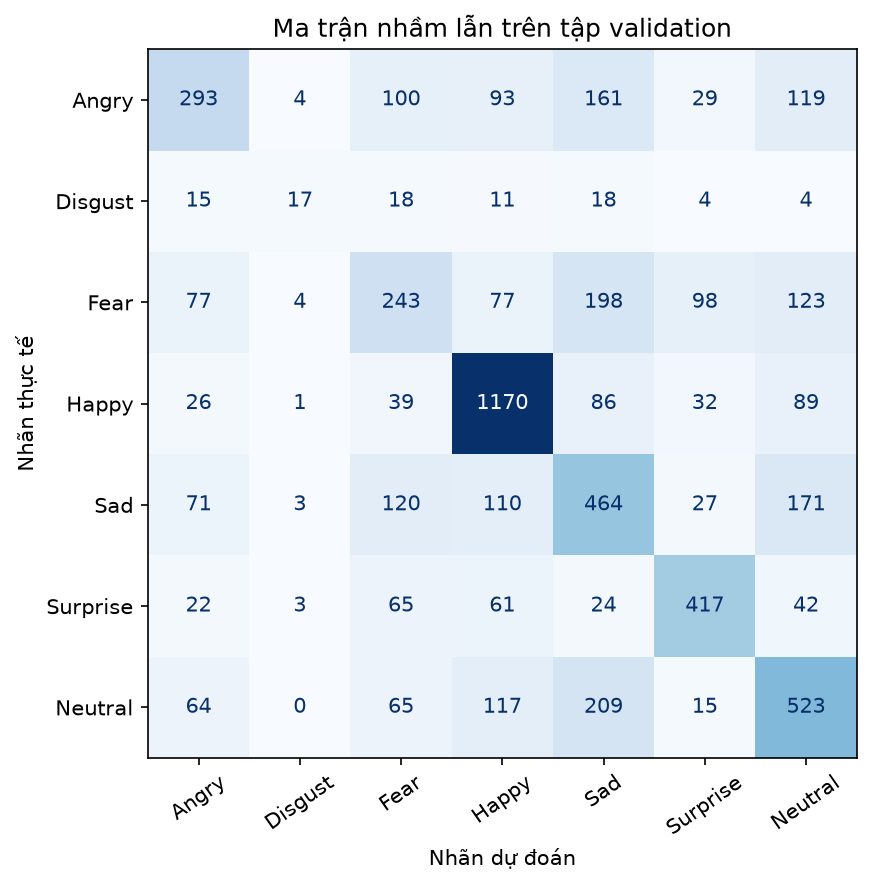

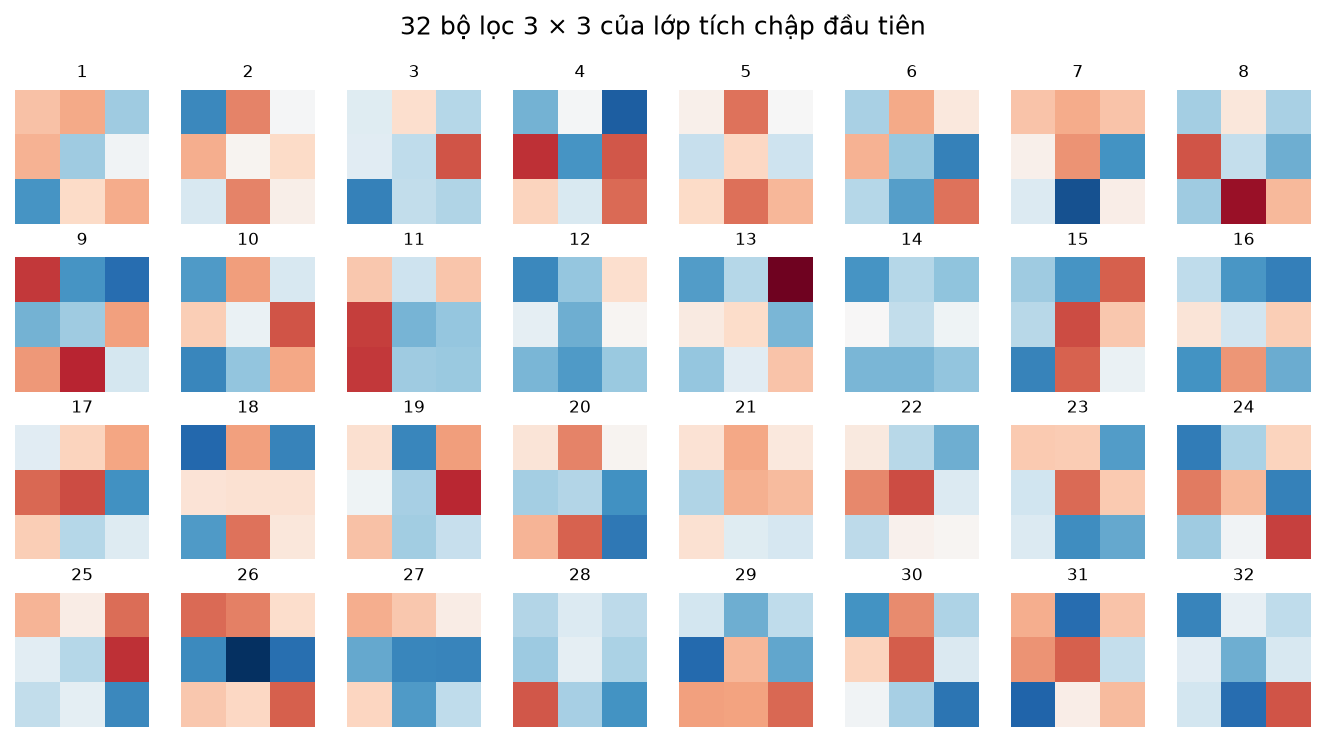

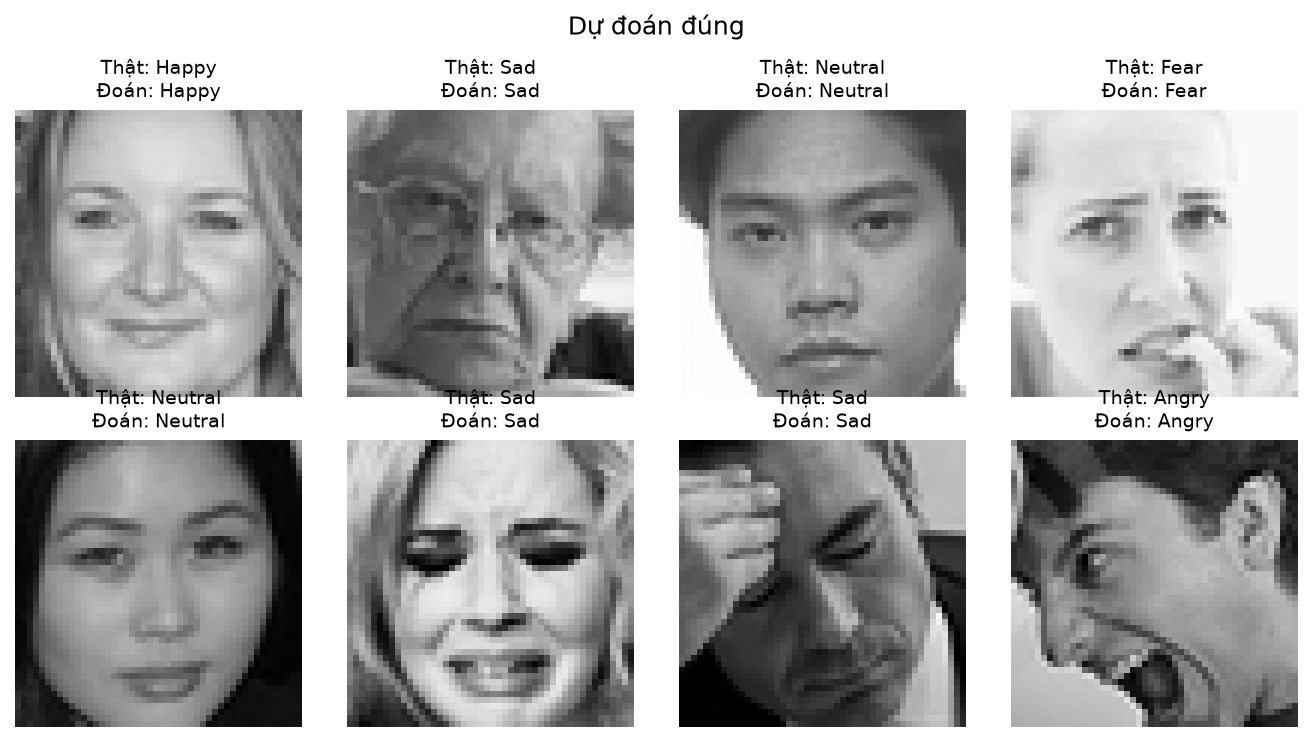

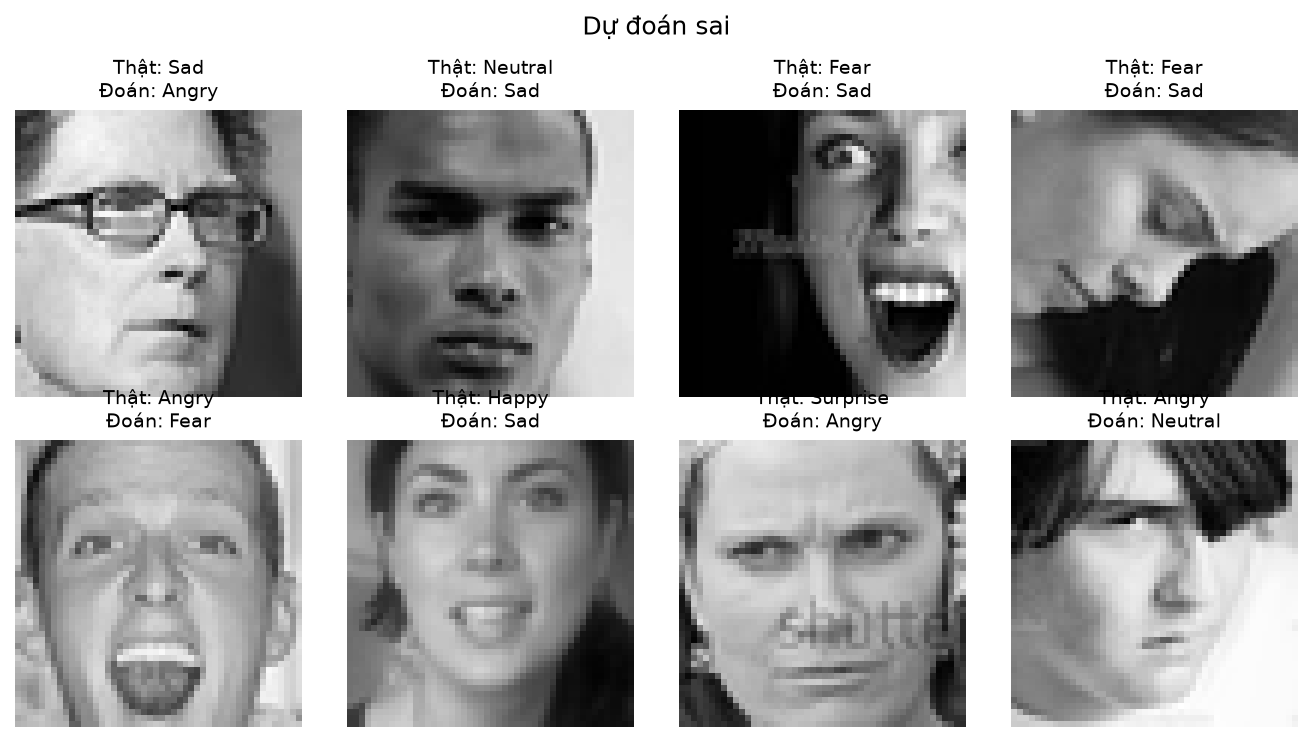

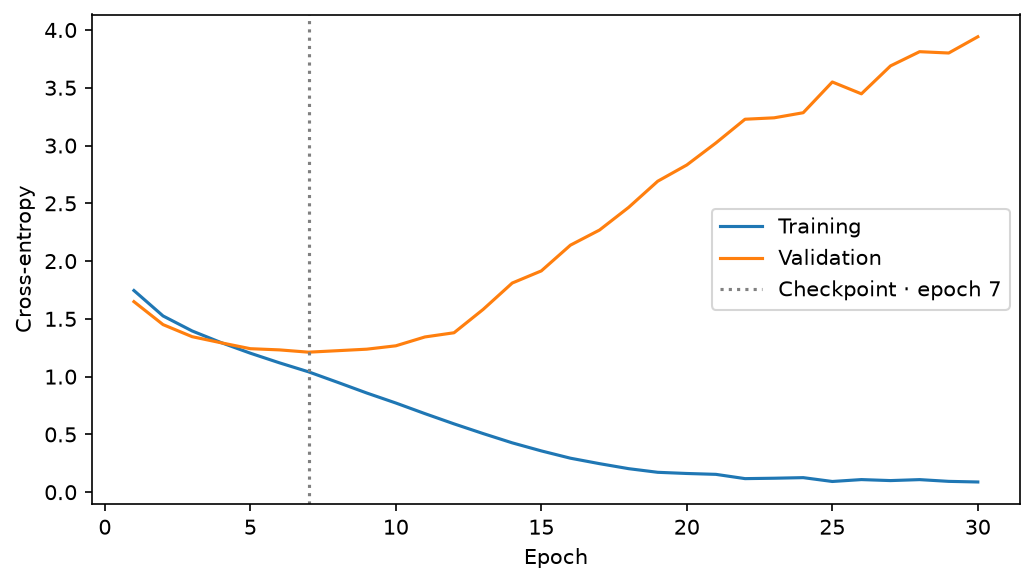

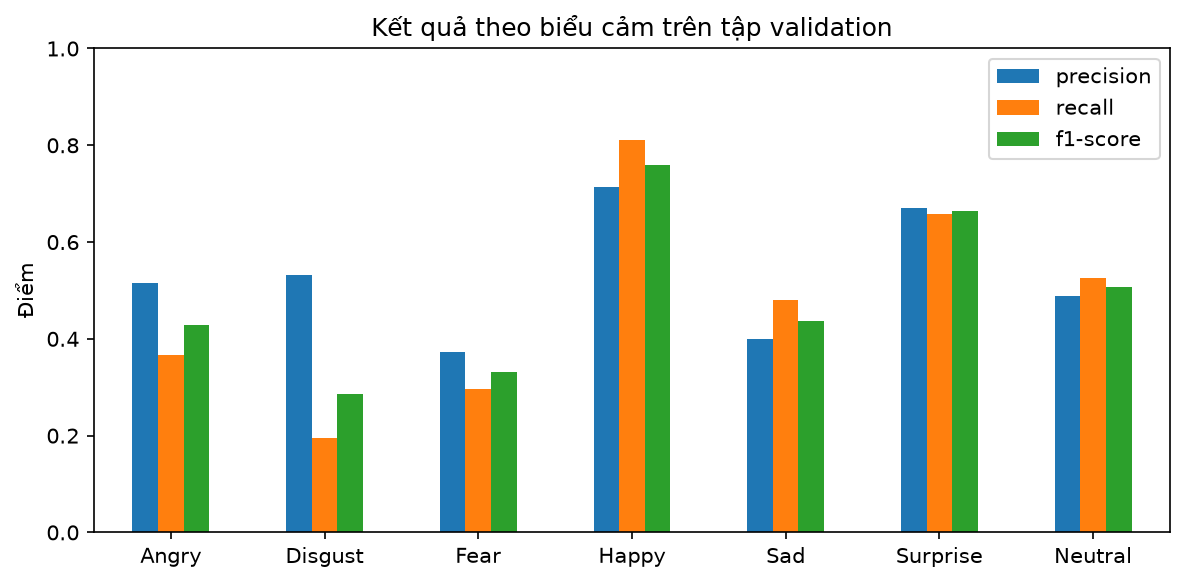

Improved V2


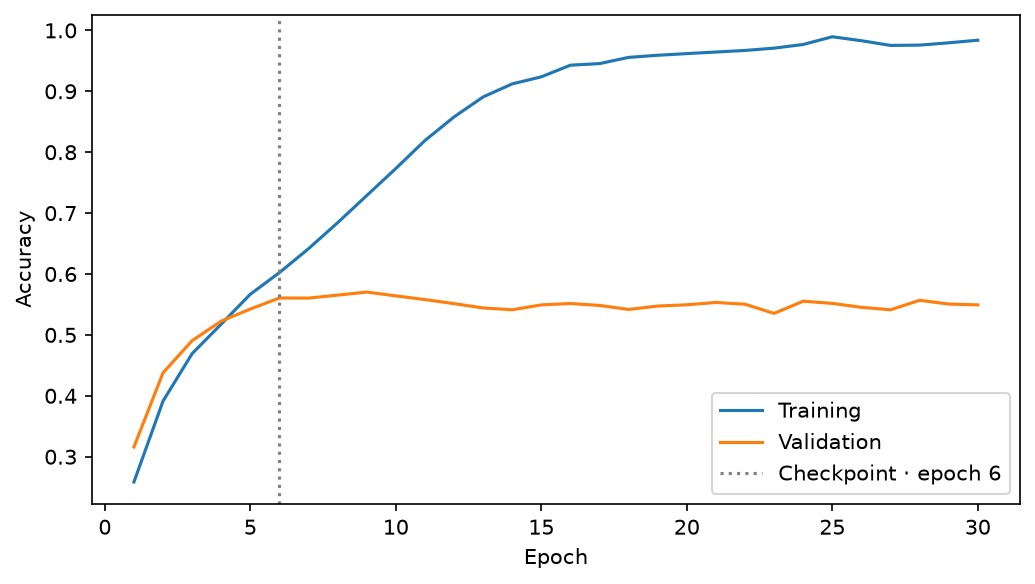

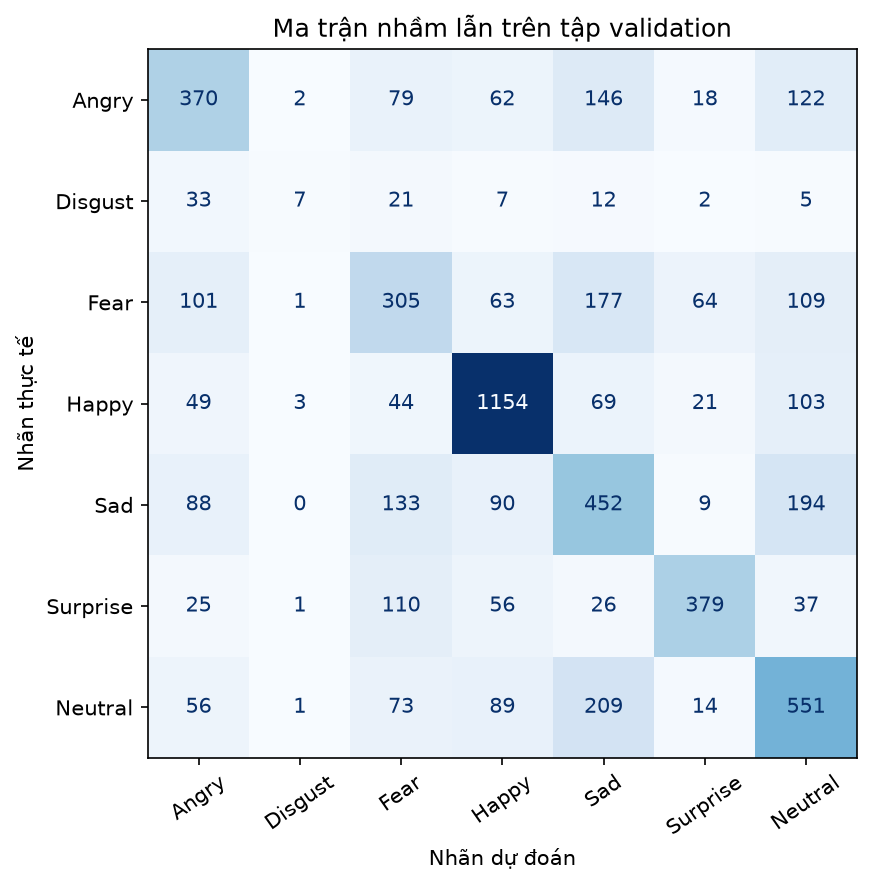

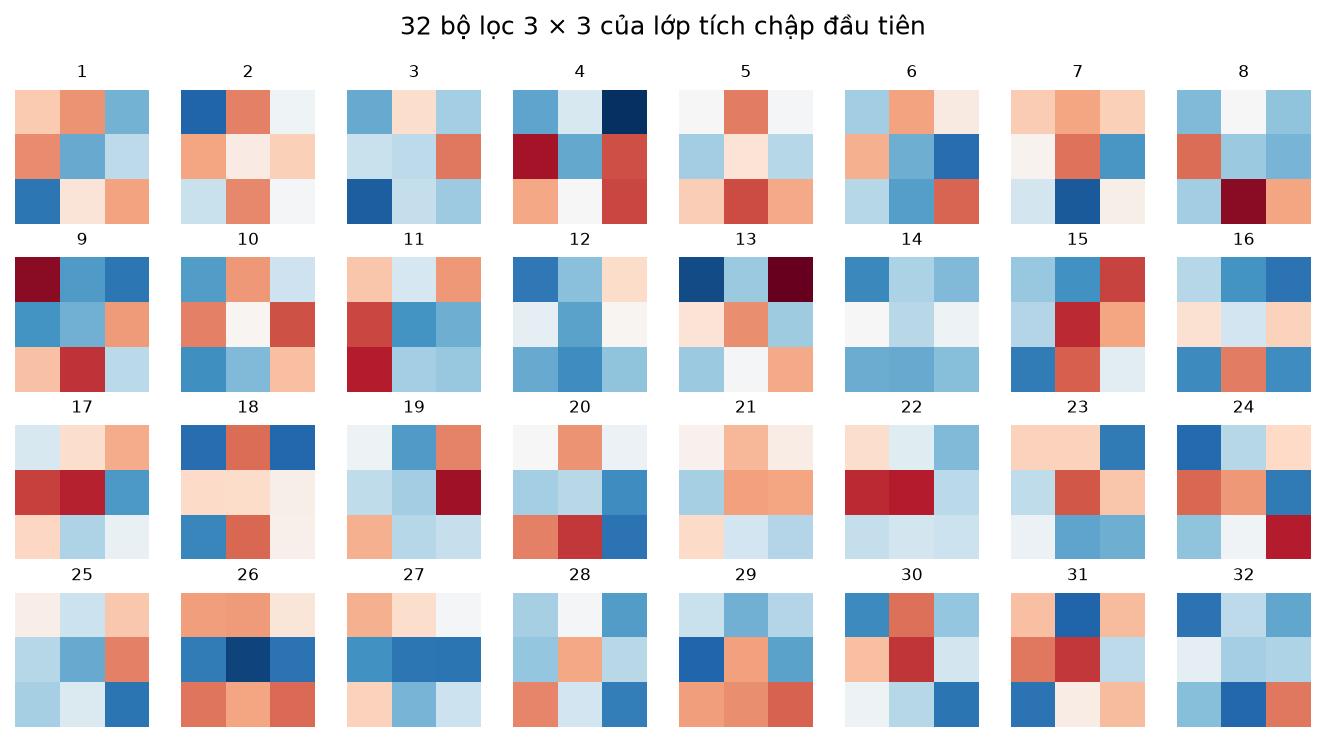

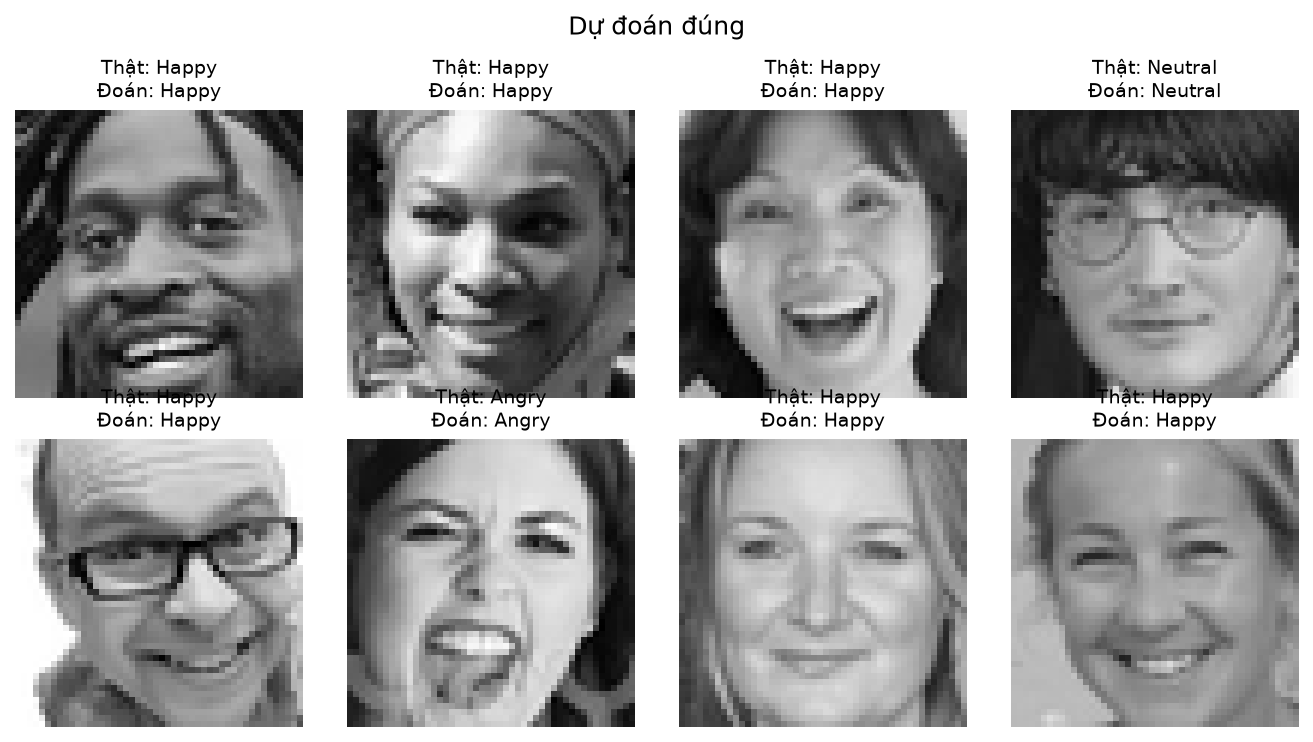

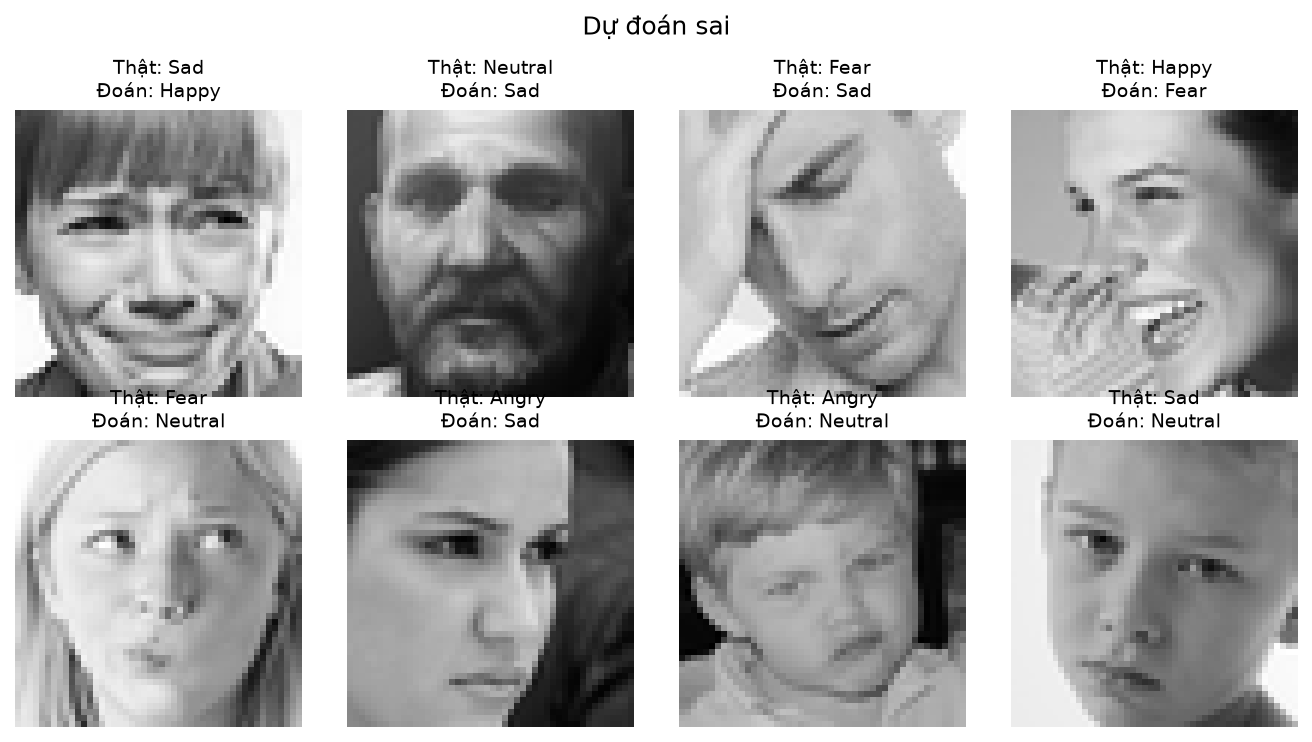

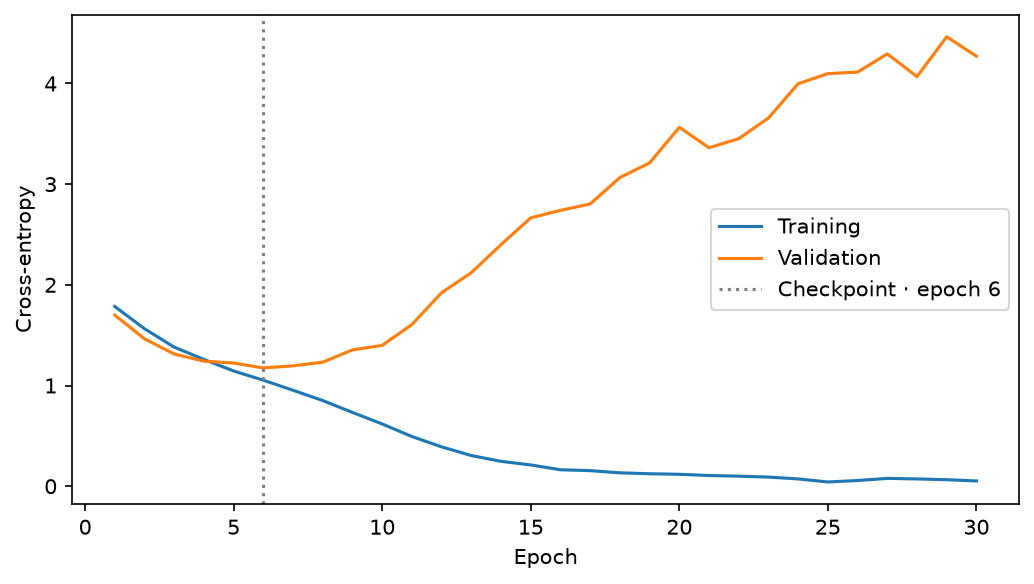

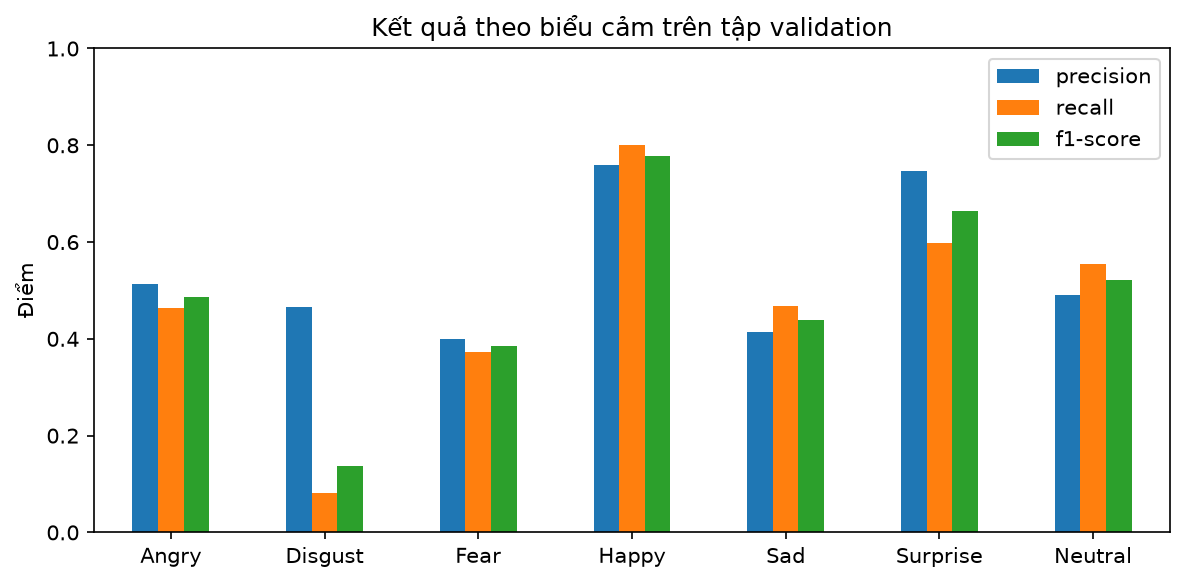

Improved V3


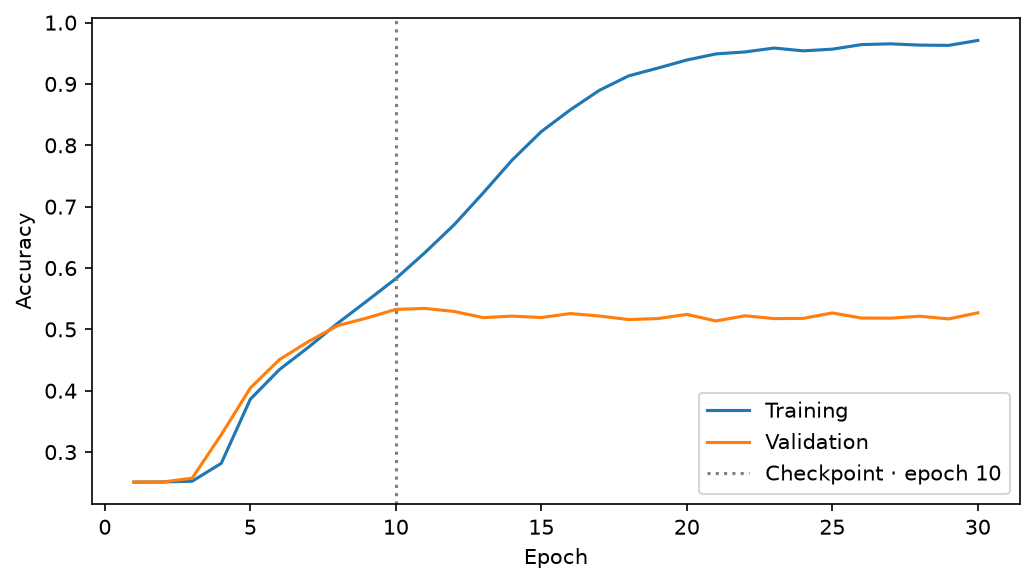

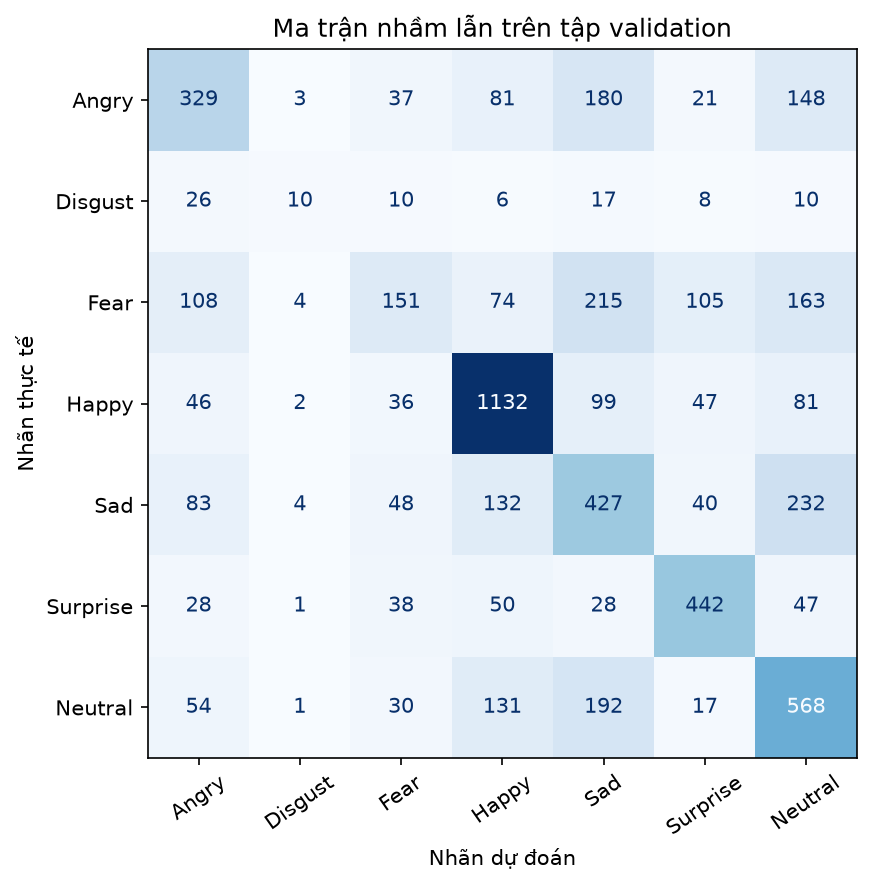

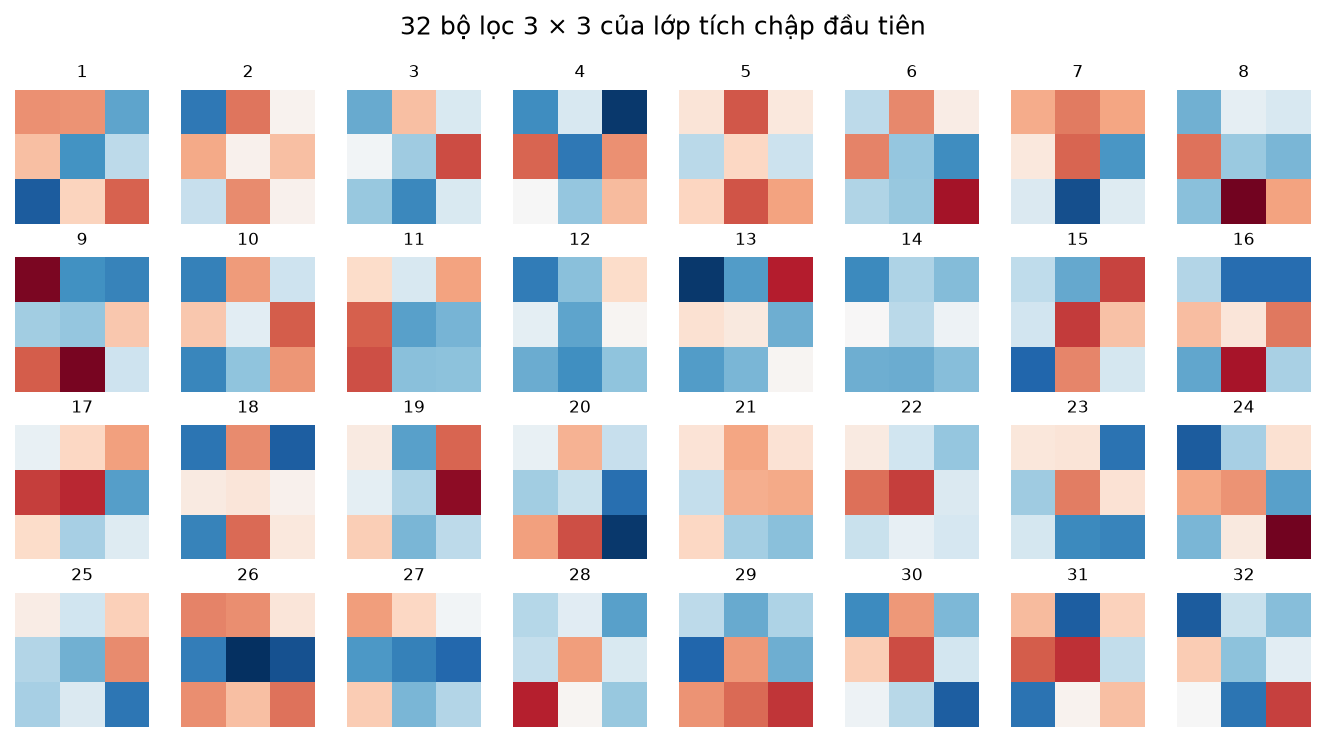

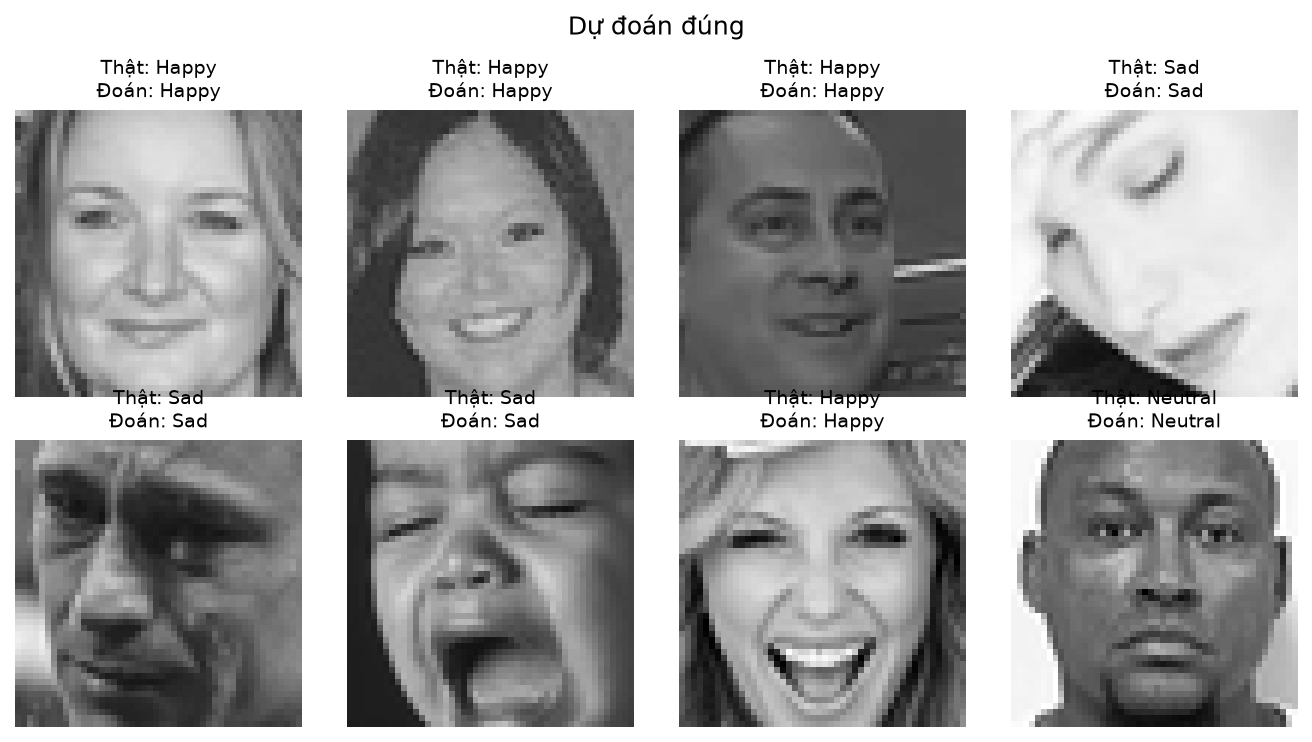

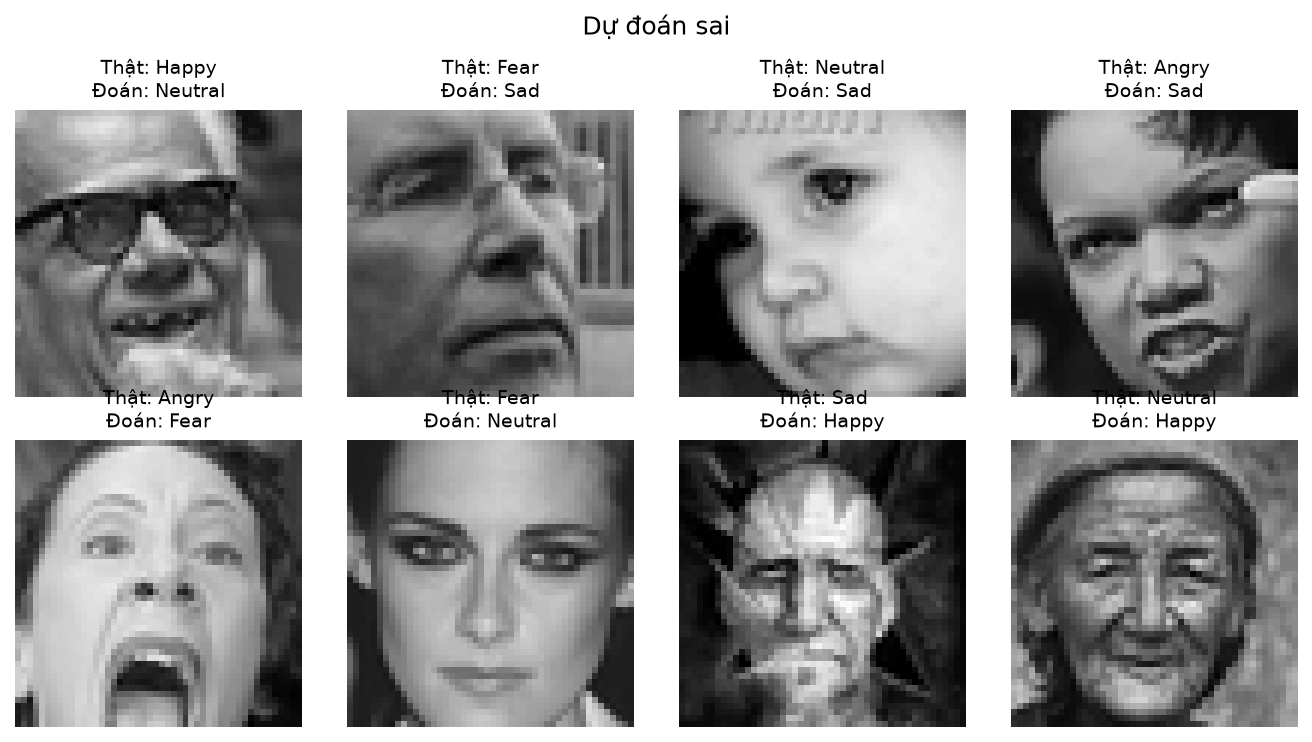

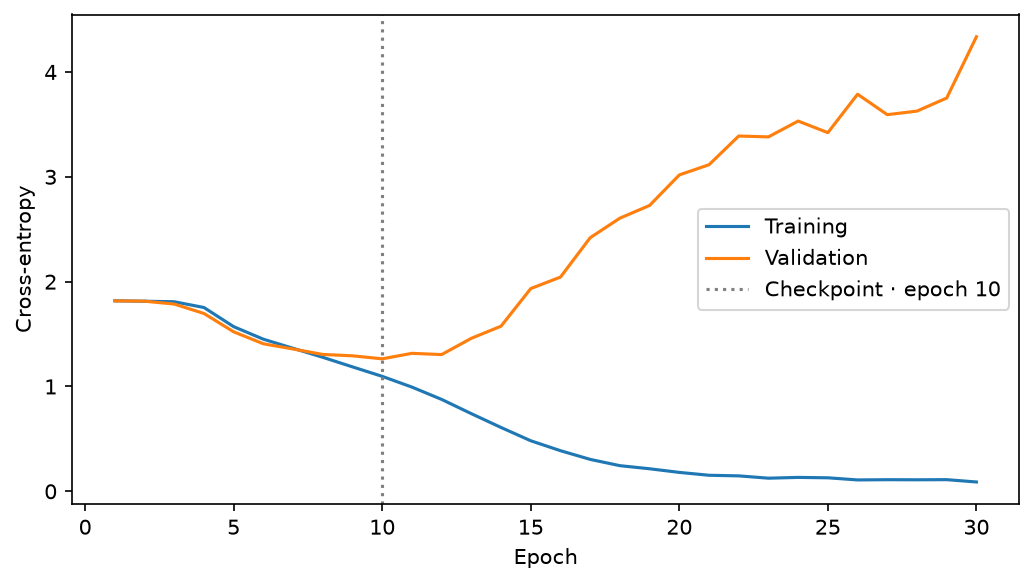

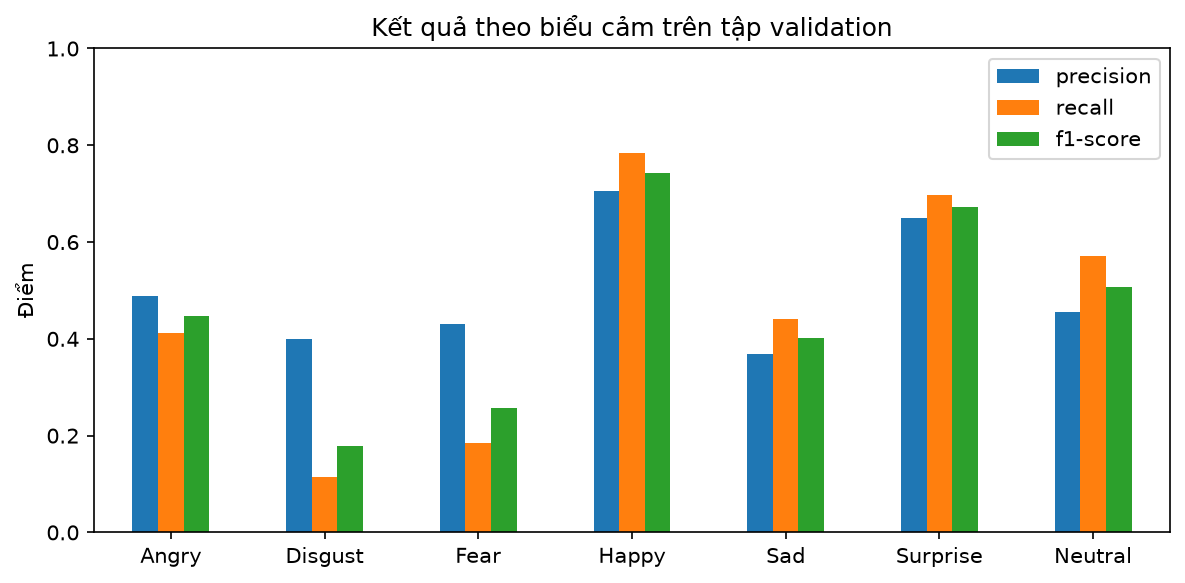

In [4]:
validation_results = {}
for name, run in runs.items():
    evaluation_path = run / "evaluation.json"
    if evaluation_path.is_file():
        saved = json.loads(evaluation_path.read_text(encoding="utf-8"))
    else:
        saved = None

    if saved is None or saved.get("split") != "validation":
        run_config = yaml.safe_load((run / "config.yaml").read_text(encoding="utf-8"))
        saved = evaluate_checkpoint(
            run,
            project / run_config["data_dir"],
            run_config["batch_size"],
            select_device(run_config.get("device", "auto")),
            split="validation",
        )
    validation_results[name] = saved

validation_summary = pd.DataFrame.from_dict(
    {
        name: {
            "Validation accuracy (%)": 100 * result["accuracy"],
            "Validation macro F1": result["macro_f1"],
        }
        for name, result in validation_results.items()
    },
    orient="index",
)
display(validation_summary.round(4))

for name, run in runs.items():
    print(name)
    display_saved_figures(run)

## So sánh các mô hình trên validation

Đối chiếu validation loss thấp nhất, accuracy và macro F1. Hai cột Δ tính chênh lệch loss/accuracy so với baseline. Đường dọc trên biểu đồ đánh dấu epoch được chọn theo validation loss. Chỉ so sánh thời gian huấn luyện khi phần cứng và môi trường tương đương.

In [5]:
comparison = {}
histories = {}
for name, run in runs.items():
    summary = json.loads((run / "training.json").read_text(encoding="utf-8"))
    history = pd.read_csv(run / "history.csv")
    best = history.loc[history["epoch"] == summary["best_epoch"]].iloc[0]
    histories[name] = history
    comparison[name] = {
        "Epoch được chọn": summary["best_epoch"],
        "Validation loss": best["val_loss"],
        "Validation accuracy (%)": 100 * best["val_accuracy"],
        "Validation macro F1": validation_results[name]["macro_f1"],
        "Số tham số": summary["parameters"],
        "Thời gian (giây)": summary["training_seconds"],
        "Thiết bị": summary["hardware"],
        "PyTorch": summary["torch"],
    }

table = pd.DataFrame.from_dict(comparison, orient="index")
table["Δ loss"] = table["Validation loss"] - table.loc[baseline_name, "Validation loss"]
table["Δ accuracy (điểm %)"] = (
    table["Validation accuracy (%)"] - table.loc[baseline_name, "Validation accuracy (%)"]
)
display(table.round(4))

,Epoch được chọn,Validation loss,Validation accuracy (%),Validation macro F1,Số tham số,Thời gian (giây),Thiết bị,PyTorch,Δ loss,Δ accuracy (điểm %)
Baseline,8,1.1995,55.2072,0.4861,683527,1570.0759,CPU,2.14.0+cpu,0.0000,0.0000
DeeperCNN,7,1.2117,54.4758,0.4874,831111,103.5085,NVIDIA GeForce RTX 3050 Laptop GPU,2.11.0,0.0122,-0.7315
Improved V2,6,1.1746,56.0606,0.4875,877287,185.9099,NVIDIA GeForce RTX 3050 Laptop GPU,2.11.0,-0.0250,0.8534
Improved V3,10,1.2639,53.2567,0.4582,1467623,229.7135,NVIDIA GeForce RTX 3050 Laptop GPU,2.11.0,0.0644,-1.9505


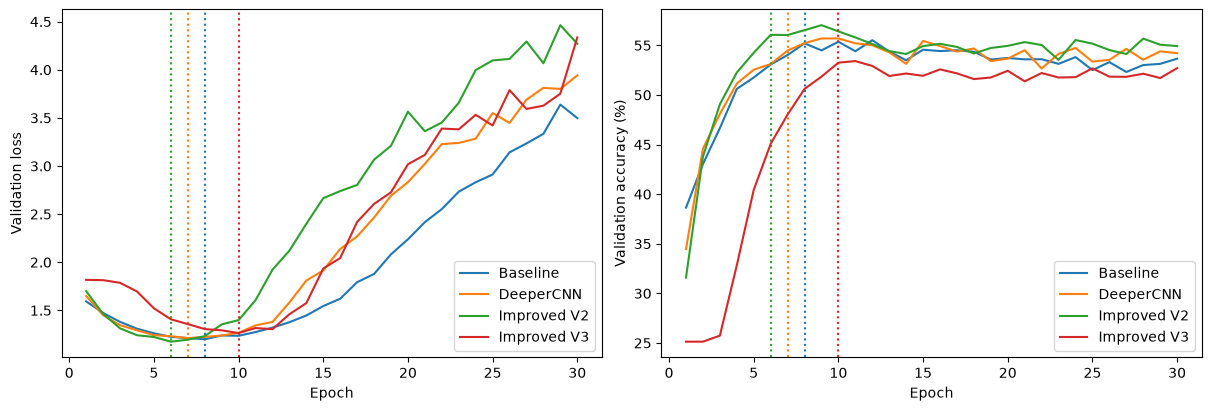

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, metric, label in zip(
    axes, ("val_loss", "val_accuracy"), ("Validation loss", "Validation accuracy (%)")
):
    for name, history in histories.items():
        values = history[metric] * 100 if metric == "val_accuracy" else history[metric]
        line, = ax.plot(history["epoch"], values, label=name)
        ax.axvline(comparison[name]["Epoch được chọn"], color=line.get_color(), linestyle=":")
    ax.set(xlabel="Epoch", ylabel=label)
    ax.legend()
plt.show()